# Binary Logistic Regression: Hypertension Prediction from Messy Healthcare Records

This notebook covers two tasks:

1. **Data cleaning** of a deliberately messy healthcare dataset: inconsistent age values, mixed date formats, blood pressure stored as text, and missing values.
2. **Binary logistic regression** to predict whether a patient's recorded condition is **Hypertension**.

The key lesson is in the evaluation. A careful, leakage-free pipeline is compared against a naive baseline to check whether the features carry any real predictive signal.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, balanced_accuracy_score)

## 2. Load and Inspect Data

In [2]:
df = pd.read_csv('healthcare_messy_data.csv')
df.head(10)

,Patient Name,Age,Gender,Condition,Medication,Visit Date,Blood Pressure,Cholesterol,Email,Phone Number
0,david lee,25,Other,Heart Disease,METFORMIN,01/15/2020,140/90,200.0,name@hospital.org,555-555-5555
1,emily davis,NaN,Male,Diabetes,NONE,"April 5, 2018",120/80,200.0,NaN,NaN
2,laura martinez,35,Other,Asthma,METFORMIN,2019.12.01,110/70,160.0,contact@domain.com,NaN
3,michael wilson,NaN,Male,Diabetes,ALBUTEROL,01/15/2020,110/70,NaN,name@hospital.org,555-555-5555
4,david lee,NaN,Female,Asthma,NONE,2020/02/20,110/70,180.0,NaN,
5,mary clark,NaN,Male,Hypertension,METFORMIN,03-25-2019,140/90,180.0,NaN,NaN
6,robert brown,NaN,Male,Hypertension,LISINOPRIL,2020/02/20,120/80,NaN,name@hospital.org,NaN
7,david lee,60,Other,NaN,NONE,2020/02/20,NaN,NaN,name@hospital.org,NaN
8,laura martinez,60,Other,Heart Disease,NONE,01/15/2020,140/90,180.0,name@hospital.org,NaN
9,michael wilson,forty,Female,NaN,ALBUTEROL,2020/02/20,140/90,220.0,patient@example.com,555-555-5555


In [3]:
df.info()
print("\nMissing values per column:")
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Patient Name    1000 non-null   object 
 1   Age             841 non-null    object 
 2   Gender          1000 non-null   object 
 3   Condition       794 non-null    object 
 4   Medication      1000 non-null   object 
 5   Visit Date      1000 non-null   object 
 6   Blood Pressure  834 non-null    object 
 7   Cholesterol     769 non-null    float64
 8   Email           616 non-null    object 
 9   Phone Number    821 non-null    object 
dtypes: float64(1), object(9)
memory usage: 78.3+ KB

Missing values per column:
Patient Name        0
Age               159
Gender              0
Condition         206
Medication          0
Visit Date          0
Blood Pressure    166
Cholesterol       231
Email             384
Phone Number      179
dtype: int64


## 3. Data Cleaning

### 3.1 Drop Identifier and Contact Columns

`Patient Name`, `Email`, and `Phone Number` are identifiers and contact details. They have no medical meaning and could let a model memorize individuals, so they are removed. The dataset has only a handful of distinct names repeated across 1,000 rows, which confirms they are placeholders.

In [4]:
print("Distinct patient names:", df['Patient Name'].nunique())

df1 = df.drop(columns=['Patient Name', 'Email', 'Phone Number'])
df1.columns = df1.columns.str.replace(' ', '_').str.lower()
df1.head()

Distinct patient names: 10


,age,gender,condition,medication,visit_date,blood_pressure,cholesterol
0,25,Other,Heart Disease,METFORMIN,01/15/2020,140/90,200.0
1,NaN,Male,Diabetes,NONE,"April 5, 2018",120/80,200.0
2,35,Other,Asthma,METFORMIN,2019.12.01,110/70,160.0
3,NaN,Male,Diabetes,ALBUTEROL,01/15/2020,110/70,NaN
4,NaN,Female,Asthma,NONE,2020/02/20,110/70,180.0


### 3.2 Age

Age is stored as text and includes the word `'forty'`. It is converted to numbers here. Missing ages are **not** filled yet: imputation happens later inside the model pipeline, using statistics from the training data only.

In [5]:
print("Raw age values:", df1['age'].unique())

df1['age'] = pd.to_numeric(df1['age'].replace({'forty': 40}), errors='coerce')
print("Cleaned age values:", sorted(df1['age'].dropna().unique()))
print("Missing ages:", df1['age'].isna().sum())

Raw age values: ['25' nan '35' '60' 'forty' '70']
Cleaned age values: [25.0, 35.0, 40.0, 60.0, 70.0]
Missing ages: 159


### 3.3 Gender and Medication

`'Other'` is a valid gender category and `'NONE'` means the patient takes no medication. Both are **real information, not missing values**, so they are kept as their own categories rather than overwritten with the most frequent value.

In [6]:
print(df1['gender'].value_counts(), "\n")
print(df1['medication'].value_counts())

gender
Female    348
Male      343
Other     309
Name: count, dtype: int64 

medication
ATORVASTATIN    216
METFORMIN       211
NONE            199
ALBUTEROL       187
LISINOPRIL      187
Name: count, dtype: int64


### 3.4 Blood Pressure: Split Text into Systolic and Diastolic

In [7]:
bp = df1['blood_pressure'].str.split('/', expand=True).astype(float)
df1['systolic_bp'] = bp[0]
df1['diastolic_bp'] = bp[1]
df1 = df1.drop(columns='blood_pressure')
df1[['systolic_bp', 'diastolic_bp']].describe()

,systolic_bp,diastolic_bp
count,834.000000,834.000000
mean,125.371703,81.420863
std,11.467097,7.554625
min,110.000000,70.000000
25%,110.000000,70.000000
50%,130.000000,85.000000
75%,140.000000,90.000000
max,140.000000,90.000000


### 3.5 Visit Date: Parse Mixed Formats

In [8]:
print("Example raw formats:", df1['visit_date'].unique()[:6])

df1['visit_date'] = pd.to_datetime(df1['visit_date'], format='mixed')
df1['visit_year'] = df1['visit_date'].dt.year
df1 = df1.drop(columns='visit_date')
print("Unparsed dates:", df1['visit_year'].isna().sum())
print(df1['visit_year'].value_counts().sort_index())

Example raw formats: ['01/15/2020' 'April 5, 2018' '2019.12.01' '2020/02/20' '03-25-2019']


Unparsed dates:

 0
visit_year
2018    210
2019    409
2020    381
Name: count, dtype: int64


### 3.6 Define the Target

Target: **`has_hypertension`** = 1 if the recorded condition is Hypertension, else 0.

Rows with a missing condition are **dropped**, not filled with the most common condition. Filling a target with the mode would invent labels and bias the model.

In [9]:
print("Rows with missing condition:", df1['condition'].isna().sum())
df1 = df1.dropna(subset=['condition']).reset_index(drop=True)

df1['has_hypertension'] = (df1['condition'] == 'Hypertension').astype(int)
df1 = df1.drop(columns='condition')

print("Rows remaining:", len(df1))
print(df1['has_hypertension'].value_counts(normalize=True).round(3))
df1.head()

Rows with missing condition: 206
Rows remaining: 794
has_hypertension
0    0.785
1    0.215
Name: proportion, dtype: float64


,age,gender,medication,cholesterol,systolic_bp,diastolic_bp,visit_year,has_hypertension
0,25.0,Other,METFORMIN,200.0,140.0,90.0,2020,0
1,NaN,Male,NONE,200.0,120.0,80.0,2018,0
2,35.0,Other,METFORMIN,160.0,110.0,70.0,2019,0
3,NaN,Male,ALBUTEROL,NaN,110.0,70.0,2020,0
4,NaN,Female,NONE,180.0,110.0,70.0,2020,0


## 4. Exploratory Analysis: Is There Any Signal?

Before modeling, test whether each feature is associated with the target. A chi-square test of independence is used for categorical features; numeric features have only a few distinct values, so they are treated as categories as well.

In [10]:
rows = []
for col in ['age', 'gender', 'medication', 'cholesterol', 'systolic_bp', 'diastolic_bp', 'visit_year']:
    table = pd.crosstab(df1[col].astype(str), df1['has_hypertension'])
    chi2, p, dof, _ = chi2_contingency(table)
    rows.append({'Feature': col, 'Chi-square': chi2, 'dof': dof, 'p-value': p})
assoc = pd.DataFrame(rows).sort_values('p-value')
print(assoc.round(4).to_string(index=False))

     Feature  Chi-square  dof  p-value
      gender      2.2850    2   0.3190
         age      4.7305    5   0.4496
  visit_year      1.3602    2   0.5066
 cholesterol      2.9468    4   0.5668
 systolic_bp      1.4528    4   0.8350
diastolic_bp      1.4528    4   0.8350
  medication      1.3077    4   0.8601


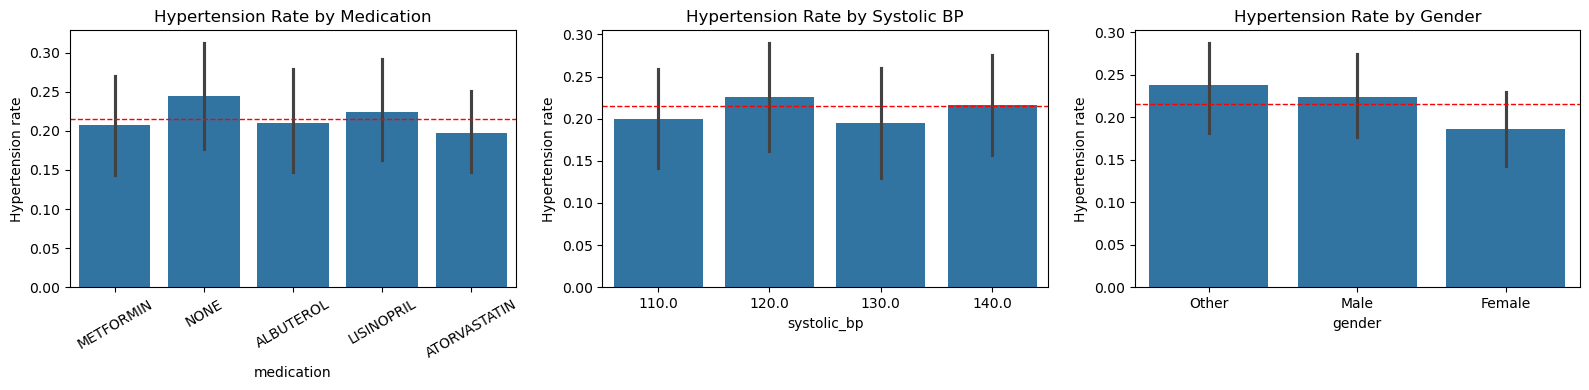

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(data=df1, x='medication', y='has_hypertension', ax=axes[0])
axes[0].set_title('Hypertension Rate by Medication')
axes[0].tick_params(axis='x', rotation=30)
sns.barplot(data=df1, x='systolic_bp', y='has_hypertension', ax=axes[1])
axes[1].set_title('Hypertension Rate by Systolic BP')
sns.barplot(data=df1, x='gender', y='has_hypertension', ax=axes[2])
axes[2].set_title('Hypertension Rate by Gender')
for ax in axes:
    ax.set_ylabel('Hypertension rate')
    ax.axhline(df1['has_hypertension'].mean(), color='red', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

## 5. Modeling

### 5.1 Train/Test Split and Preprocessing Pipeline

The data is split **before** any imputation or scaling. All preprocessing lives inside a `ColumnTransformer`, so it is fitted on training data only:

* **Numeric features:** median imputation, then standardization.
* **Categorical features:** most-frequent imputation, then one-hot encoding.

`class_weight='balanced'` compensates for hypertension being the minority class.

In [12]:
numeric_features = ['age', 'cholesterol', 'systolic_bp', 'diastolic_bp', 'visit_year']
categorical_features = ['gender', 'medication']

X = df1[numeric_features + categorical_features]
y = df1['has_hypertension']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

preprocess = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), numeric_features),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_features),
])

log_model = Pipeline([
    ('prep', preprocess),
    ('logreg', LogisticRegression(class_weight='balanced', max_iter=1000))
])

dummy_model = Pipeline([
    ('prep', preprocess),
    ('dummy', DummyClassifier(strategy='stratified', random_state=42))
])
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (635, 7)  Test: (159, 7)


### 5.2 Cross-Validation: Logistic Regression vs. Random Baseline

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['roc_auc', 'balanced_accuracy']

results = []
for name, model in [('Random baseline (Dummy)', dummy_model), ('Logistic Regression', log_model)]:
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    results.append({
        'Model': name,
        'CV ROC AUC': f"{res['test_roc_auc'].mean():.4f} ± {res['test_roc_auc'].std():.4f}",
        'CV Balanced Accuracy': f"{res['test_balanced_accuracy'].mean():.4f} ± {res['test_balanced_accuracy'].std():.4f}",
    })
print(pd.DataFrame(results).to_string(index=False))

                  Model      CV ROC AUC CV Balanced Accuracy
Random baseline (Dummy) 0.5105 ± 0.0480      0.5105 ± 0.0480
    Logistic Regression 0.4928 ± 0.0312      0.4824 ± 0.0255


### 5.3 Hold-out Test Evaluation

In [14]:
log_model.fit(X_train, y_train)
y_pred = log_model.predict(X_test)
y_prob = log_model.predict_proba(X_test)[:, 1]

print(f"Test ROC AUC           : {roc_auc_score(y_test, y_prob):.4f}")
print(f"Test Balanced Accuracy : {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Test Accuracy          : {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:\n",
      classification_report(y_test, y_pred, target_names=['No hypertension', 'Hypertension']))

Test ROC AUC           : 0.4554
Test Balanced Accuracy : 0.4792
Test Accuracy          : 0.5346

Classification Report:
                  precision    recall  f1-score   support

No hypertension       0.77      0.58      0.66       125
   Hypertension       0.20      0.38      0.26        34

       accuracy                           0.53       159
      macro avg       0.49      0.48      0.46       159
   weighted avg       0.65      0.53      0.57       159



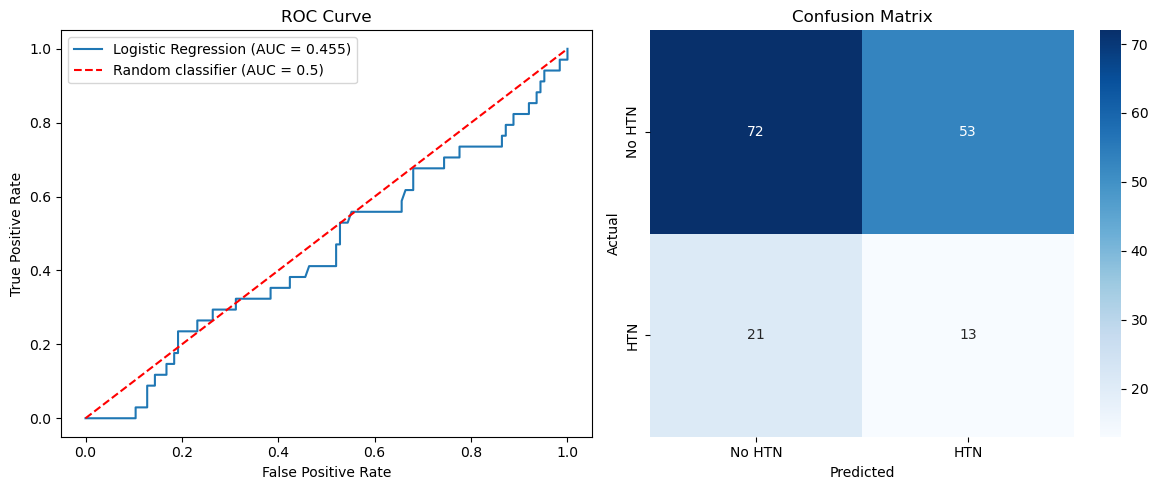

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[0].plot(fpr, tpr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_prob):.3f})')
axes[0].plot([0, 1], [0, 1], 'r--', label='Random classifier (AUC = 0.5)')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve')
axes[0].legend()

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['No HTN', 'HTN'], yticklabels=['No HTN', 'HTN'])
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')
axes[1].set_title('Confusion Matrix')
plt.tight_layout()
plt.show()

### 5.4 Coefficients

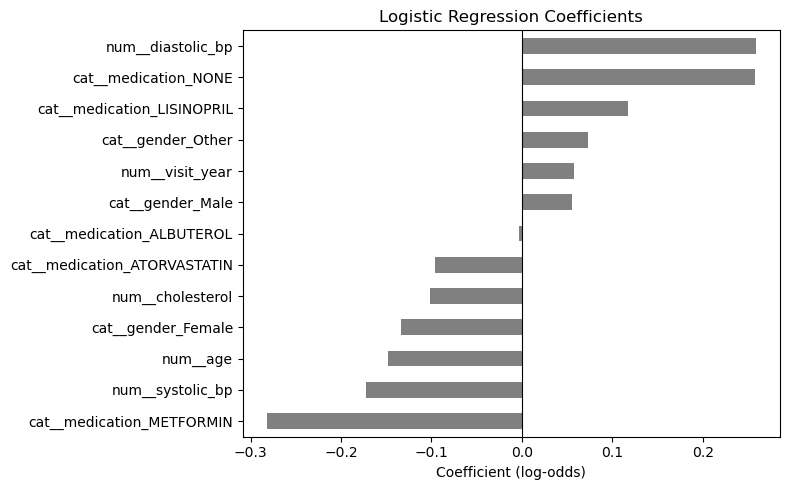

In [16]:
feature_names = log_model.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(log_model.named_steps['logreg'].coef_[0], index=feature_names).sort_values()

plt.figure(figsize=(8, 5))
coefs.plot(kind='barh', color='gray')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Coefficient (log-odds)')
plt.title('Logistic Regression Coefficients')
plt.tight_layout()
plt.show()

## 6. Conclusion

| Model | CV ROC AUC | Test ROC AUC | Test Balanced Accuracy |
|---|---|---|---|
| Random baseline (Dummy) | 0.511 | — | — |
| Logistic Regression | 0.493 | 0.455 | 0.479 |

**The model performs at chance level.** This is the correct result, not a modeling failure:

* The chi-square tests in Section 4 show that **no feature is associated with hypertension** (all p-values between 0.32 and 0.86).
* This is a **synthetic dataset built for data-cleaning practice**. Its values were generated independently of each other: 10 repeated patient names, five fixed age values, four fixed blood pressure readings.
* Even a correctly built, leakage-free pipeline cannot find signal that isn't in the data. Comparing against a dummy baseline makes this visible, instead of reporting a misleading accuracy. Accuracy alone would look acceptable because about 79% of patients are not hypertensive.

**Cleaning lessons applied in this notebook:**
* Text values were converted to numbers (`'forty'` → 40, `'140/90'` → systolic and diastolic).
* Five mixed date formats were parsed.
* `'Other'` gender and `'NONE'` medication were kept as real categories instead of being overwritten.
* Rows with a missing target were dropped instead of having labels invented for them.
* All imputation is fitted inside the pipeline, on training data only.